In [10]:
import requests
import pandas as pd



In [11]:
url = "https://api.openf1.org/v1/laps?session_key=9693"
response = requests.get(url)
laps = pd.DataFrame(response.json())

In [12]:
laps.head()

,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1254,9693,81,1,2025-03-16T04:18:22.973000+00:00,44.302,20.844,56.056,244.0,298.0,False,121.202,"[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2051, 2049, 2049, 2049, 2049]",226.0
1,1254,9693,1,1,2025-03-16T04:18:22.973000+00:00,43.749,20.705,55.250,249.0,292.0,False,119.704,"[2049, 2049, 2049, 2051, 2049, 2049, 2049, 204...","[2049, 2051, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2051, 2051, 2049]",215.0
2,1254,9693,63,1,2025-03-16T04:18:22.973000+00:00,45.130,21.030,58.930,241.0,297.0,False,125.090,"[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 2049]",207.0
3,1254,9693,22,1,2025-03-16T04:18:22.973000+00:00,45.686,21.598,63.680,211.0,291.0,False,130.964,"[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 2049]",193.0
4,1254,9693,23,1,2025-03-16T04:18:22.973000+00:00,46.220,21.334,65.027,205.0,282.0,False,132.581,"[2049, 2049, 2049, 2049, 2049, 2049, 2049, 205...","[2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 2049]",192.0


In [13]:
laps.dtypes

meeting_key            int64
session_key            int64
driver_number          int64
lap_number             int64
date_start            object
duration_sector_1    float64
duration_sector_2    float64
duration_sector_3    float64
i1_speed             float64
i2_speed             float64
is_pit_out_lap          bool
lap_duration         float64
segments_sector_1     object
segments_sector_2     object
segments_sector_3     object
st_speed             float64
dtype: object

In [ ]:
drivers = laps[laps['driver_number'].isin([4,1])]
clean_laps = drivers.loc[drivers['lap_duration'].notna() & (drivers['lap_number'] != 1) & ~(drivers['is_pit_out_lap'])]


(102, 16)

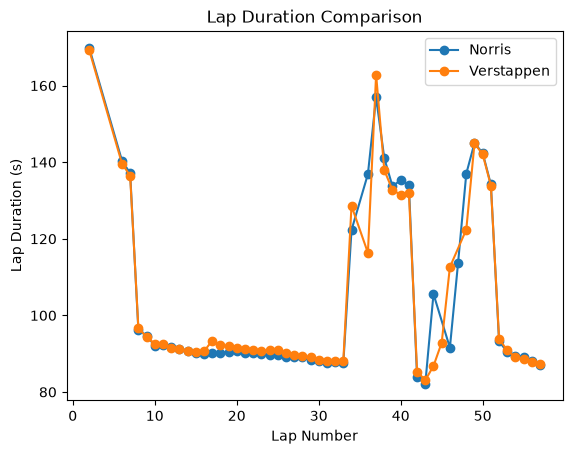

In [53]:
import matplotlib.pyplot as plt
norris = clean_laps[clean_laps['driver_number'] == 4]
verstappen = clean_laps[clean_laps['driver_number'] == 1]
plt.plot(norris['lap_number'], norris['lap_duration'], label='Norris', marker='o')
plt.plot(verstappen['lap_number'], verstappen['lap_duration'], label='Verstappen', marker='o')
plt.xlabel('Lap Number')
plt.ylabel('Lap Duration (s)')
plt.title('Lap Duration Comparison')
plt.legend()
plt.show()

In [59]:
drivers[drivers['lap_number'].isin([3, 4, 5, 35])][['lap_number', 'driver_number', 'lap_duration', 'is_pit_out_lap']]

,lap_number,driver_number,lap_duration,is_pit_out_lap
37,3,4,161.723,True
38,3,1,162.145,True
54,4,4,156.053,True
55,4,1,155.775,True
71,5,4,143.648,True
72,5,1,143.609,True
576,35,4,123.448,True
582,35,1,124.508,True


## Missing laps
The chart is missing laps 3-5 and 35. They were filtered out by `is_pit_out_lap` = True
- lap 3-5: drivers drove through pit lane behind the safety car
- lap 35: drivers pitted under safety car

The filter is left in the code as those laps were not racing under green flag. Pit stops will be counted from the pit endpoint.